# Lead Service Line Analysis

## AI-Assisted Data Story for a Public Issue

**Organization:** Xylem / IBM SkillsBuild  
**Data Source:** U.S. Environmental Protection Agency (EPA), SDWIS Service Line Inventory  
**Reporting Period:** 2026 Q2

### Research Question

**Where are lead service line infrastructure needs greatest across U.S. states?**

This analysis examines two related dimensions of that infrastructure challenge:

- **Identification need:** service lines whose material remains classified as Lead Status Unknown
- **Replacement need:** service lines already classified as Lead or Galvanized Requiring Replacement (GRR)

The analysis first compares the absolute scale of these needs across states and then examines whether the interpretation changes after accounting for state resident population.

A Lead Status Unknown service line is **not assumed to be a lead service line**. It represents a service line whose material has not yet been demonstrated to be Lead, GRR, or Non-lead.

## 1. Data Source

The primary dataset is the EPA SDWIS Service Line Inventory for 2026 Q2.

**Raw file:** `SDWIS_service_line_inventory_2026Q2.csv`

**Official source:** [U.S. EPA SDWIS Service Line Inventory](https://sdwis.epa.gov/ords/sfdw_pub/r/sfdw/sdwis_fed_reports_public/service-line-inventory)

The original CSV is preserved unchanged. All filtering, cleaning, calculations, validation checks, and aggregation are performed reproducibly within this notebook.

Relevant fields include:

- Lead service lines
- Galvanized Requiring Replacement (GRR) service lines
- Lead Status Unknown service lines
- Non-lead service lines
- Total reported service lines
- Public Water System (PWS) type
- Service-line reporting status
- Primacy agency
- EPA region
- Population served

The analysis focuses on reported infrastructure inventories. It does not measure household lead exposure, drinking-water lead concentrations, or health risk.

## 2. Analytical Framework

Lead service line infrastructure need is treated as a multidimensional issue rather than a single ranking.

For this analysis:

**Known Replacement Inventory = Lead Service Lines + Galvanized Requiring Replacement Service Lines**

This represents service lines already classified into categories requiring lead-related replacement action.

**Identification Need = Lead Status Unknown Service Lines**

This represents service lines whose material classification remains unresolved.

These measures represent different stages of the same infrastructure process:

**Unknown → Identify material → Classify as Lead / GRR / Non-lead → Replace where required**

The analysis does not combine replacement and identification needs into a single composite score.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

Path("outputs").mkdir(exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


## 3. Load Raw Data

The EPA CSV is loaded directly from the preserved raw file.

The file requires `cp1252` character encoding. `low_memory=False` is used so pandas reads the dataset without chunk-based type inference.

No cleaning or transformations are performed during this step.

In [2]:
raw_df = pd.read_csv(
    "SDWIS_service_line_inventory_2026Q2.csv",
    encoding="cp1252",
    low_memory=False
)

print(f"Rows: {raw_df.shape[0]:,}")
print(f"Columns: {raw_df.shape[1]}")

Rows: 66,429
Columns: 22


In [3]:
raw_df["Submission Year Quarter"].value_counts(dropna=False)

Submission Year Quarter
2026Q2    66429
Name: count, dtype: int64

## 4. Initial Data Inspection

Before filtering or cleaning, the raw dataset is inspected for its structure, data types, missing values, and reporting completeness.

In [4]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66429 entries, 0 to 66428
Data columns (total 22 columns):
 #   Column                                            Non-Null Count  Dtype 
---  ------                                            --------------  ----- 
 0   Submission Year Quarter                           66429 non-null  object
 1   PWS ID                                            66429 non-null  object
 2   PWS Name                                          66429 non-null  object
 3   # Galvanized Requiring Replacement Service Lines  59062 non-null  object
 4   # Lead Service Lines                              58918 non-null  object
 5   # Lead Status Unknown Service Lines               59652 non-null  object
 6   # Non-lead Service Lines                          59620 non-null  object
 7   Total # Service Lines Reported                    60109 non-null  object
 8   Any Service Line Type Reported                    66429 non-null  object
 9   Service Line Report Status  

In [5]:
relevant_columns = [
    "# Lead Service Lines",
    "# Galvanized Requiring Replacement Service Lines",
    "# Lead Status Unknown Service Lines",
    "# Non-lead Service Lines",
    "Total # Service Lines Reported",
    "Population Served Count"
]

raw_df[relevant_columns].isna().sum()

# Lead Service Lines                                7511
# Galvanized Requiring Replacement Service Lines    7367
# Lead Status Unknown Service Lines                 6777
# Non-lead Service Lines                            6809
Total # Service Lines Reported                      6320
Population Served Count                                0
dtype: int64

In [6]:
raw_df["PWS Type"].value_counts()

PWS Type
Community water system                49378
Non-Transient non-community system    17051
Name: count, dtype: int64

In [7]:
raw_df["Service Line Report Status"].value_counts()

Service Line Report Status
Reported all required service line types          58825
Did not report any required service line types     6674
Reported some but not all service line types        930
Name: count, dtype: int64

### Initial Inspection Notes

The raw file contains multiple water-system types and reporting-completeness levels. Several service-line count fields also contain missing values and are stored as text because some values include commas.

The analysis will therefore restrict the sample to Community Water Systems with complete required service-line reporting, preserve missing values during numeric conversion, and explicitly limit the geographic comparison to the 50 states and District of Columbia.

## 5. Define Analytical Scope

The main analysis focuses on Community Water Systems with complete required service-line reporting in the 50 U.S. states and District of Columbia.

These filters are applied sequentially so the effect of each scope decision can be verified.

In [8]:
df = raw_df[
    raw_df["PWS Type"] == "Community water system"
].copy()

print(f"Community Water Systems: {len(df):,}")

Community Water Systems: 49,378

In [9]:
df = df[
    df["Service Line Report Status"] == "Reported all required service line types"
].copy()

print(f"Complete Community Water System reports: {len(df):,}")

Complete Community Water System reports: 44,957


In [10]:
states_dc = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "District of Columbia", "Florida", "Georgia",
    "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky",
    "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
    "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
    "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island",
    "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont",
    "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"
]

df = df[df["Primacy Agency"].isin(states_dc)].copy()

print(f"Final analytical sample: {len(df):,}")

Final analytical sample: 43,993


In [11]:
print(f"Rows: {len(df):,}")
print(f"Unique PWS IDs: {df['PWS ID'].nunique():,}")
print(f"Duplicate PWS IDs: {df['PWS ID'].duplicated().sum():,}")

Rows: 43,993


Unique PWS IDs: 43,993
Duplicate PWS IDs: 0


### Scope Result

The analysis is limited to **Community Water Systems** in the **50 states and District of Columbia** that **reported all required service-line types**.

This produces a final analytical sample of **43,993 systems** and avoids treating incomplete reporting as true zero values.

Each PWS ID appears once in the final sample, so no deduplication is required.

## 6. Data Cleaning

Relevant service-line count fields are stored as text because some values contain commas. These fields are converted to numeric values while preserving missing values.

In [12]:
numeric_columns = [
    "# Galvanized Requiring Replacement Service Lines",
    "# Lead Service Lines",
    "# Lead Status Unknown Service Lines",
    "# Non-lead Service Lines",
    "Total # Service Lines Reported"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

In [13]:
pd.DataFrame({
    "Data Type": df[numeric_columns].dtypes.astype(str),
    "Missing Values": df[numeric_columns].isna().sum()
})

,Data Type,Missing Values
# Galvanized Requiring Replacement Service Lines,Int64,0
# Lead Service Lines,Int64,0
# Lead Status Unknown Service Lines,Int64,0
# Non-lead Service Lines,Int64,16
Total # Service Lines Reported,Int64,0


## 7. Derived Metrics

Two measures are used to represent different stages of lead service line infrastructure need:

- **Known Replacement Inventory** = Lead Service Lines + Galvanized Requiring Replacement Service Lines
- **Identification Need** = Lead Status Unknown Service Lines

In [14]:
df["Known Replacement Inventory"] = (
    df["# Lead Service Lines"]
    + df["# Galvanized Requiring Replacement Service Lines"]
)

df["Identification Need"] = df["# Lead Status Unknown Service Lines"]

In [15]:
category_sum = (
    df["# Lead Service Lines"]
    + df["# Galvanized Requiring Replacement Service Lines"]
    + df["# Lead Status Unknown Service Lines"]
    + df["# Non-lead Service Lines"].fillna(0)
)

total_matches = category_sum == df["Total # Service Lines Reported"]

print(f"Rows matching reported total: {total_matches.sum():,} of {len(df):,}")
print(f"Rows not matching: {(~total_matches).sum():,}")

Rows matching reported total: 43,993 of 43,993
Rows not matching: 0


### Validation

For all **43,993 systems**, the reported service-line categories reconcile with the reported total service-line count.

For the 16 records with missing Non-lead values, Lead + GRR + Unknown already equals the reported total, so the missing Non-lead field does not affect the core metrics used in this analysis.

## 8. State-Level Aggregation

System-level records are aggregated by state to compare the scale of replacement and identification needs across the 50 states and District of Columbia.

In [16]:
state_summary = (
    df.groupby("Primacy Agency")
      .agg(
          Systems=("PWS ID", "count"),
          Lead=("# Lead Service Lines", "sum"),
          GRR=("# Galvanized Requiring Replacement Service Lines", "sum"),
          Known_Replacement=("Known Replacement Inventory", "sum"),
          Unknown=("Identification Need", "sum")
      )
      .reset_index()
      .rename(columns={"Primacy Agency": "State"})
)

In [17]:
print(f"States + DC: {len(state_summary)}")
print(f"Total systems represented: {state_summary['Systems'].sum():,}")

States + DC: 51
Total systems represented: 43,993


## 9. National Inventory Context

National totals are calculated from the final analytical sample to establish the overall scale of known replacement inventory and unresolved identification need before comparing states.

In [18]:
national_totals = pd.DataFrame({
    "Category": ["Lead", "GRR", "Unknown"],
    "Service Lines": [
        df["# Lead Service Lines"].sum(),
        df["# Galvanized Requiring Replacement Service Lines"].sum(),
        df["# Lead Status Unknown Service Lines"].sum()
    ]
})

national_totals

,Category,Service Lines
0,Lead,2179217
1,GRR,936091
2,Unknown,21589524


In [19]:
national_known_replacement = (
    national_totals.loc[
        national_totals["Category"].isin(["Lead", "GRR"]),
        "Service Lines"
    ].sum()
)

print(f"Known Replacement Inventory: {national_known_replacement:,.0f}")
print(f"Identification Need: {national_totals.loc[national_totals['Category'] == 'Unknown', 'Service Lines'].iloc[0]:,.0f}")

Known Replacement Inventory: 3,115,308
Identification Need: 21,589,524


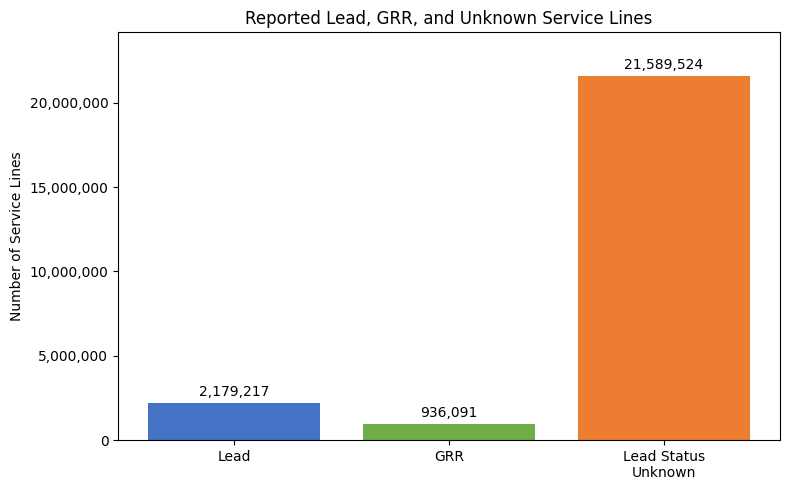

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

display_categories = ["Lead", "GRR", "Lead Status\nUnknown"]

bars = ax.bar(
    display_categories,
    national_totals["Service Lines"],
    color=["#4472C4", "#70AD47", "#ED7D31"]
)

ax.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in national_totals["Service Lines"]],
    padding=3
)

ax.set_ylim(
    0,
    national_totals["Service Lines"].max() * 1.12
)

ax.set_title("Reported Lead, GRR, and Unknown Service Lines")
ax.set_ylabel("Number of Service Lines")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

fig.tight_layout()
fig.savefig("outputs/chart_1_inventory.png", dpi=300, bbox_inches="tight")
plt.show()

### Initial Finding

Within the analytical sample, approximately **3.1 million service lines are already classified as Lead or GRR**, while approximately **21.6 million remain classified as Lead Status Unknown**. The much larger unknown inventory indicates that unresolved identification is a major part of the reported infrastructure picture, but unknown lines should not be interpreted as confirmed lead lines.

## 10. State-Level Infrastructure Needs

State totals are compared to identify where known replacement inventories and unresolved identification needs are most concentrated.

In [21]:
state_summary.sort_values(
    "Known_Replacement",
    ascending=False
)[
    ["State", "Known_Replacement", "Unknown", "Systems"]
].head(10)

,State,Known_Replacement,Unknown,Systems
13,Illinois,672210,529706,1635
35,Ohio,321502,878788,1101
32,New York,289055,951163,2211
22,Michigan,255524,301508,1349
14,Indiana,190947,545507,744
49,Wisconsin,158815,182814,1021
30,New Jersey,135360,860857,555
43,Texas,114501,2178881,4341
38,Pennsylvania,113717,2055512,1770
23,Minnesota,87183,209216,959


In [22]:
top_unknown = (
    state_summary
    .sort_values("Unknown", ascending=False)
    [["State", "Unknown", "Known_Replacement", "Systems"]]
    .head(10)
)

top_unknown

,State,Unknown,Known_Replacement,Systems
43,Texas,2178881,114501,4341
38,Pennsylvania,2055512,113717,1770
9,Florida,1665928,44559,1389
32,New York,951163,289055,2211
25,Missouri,895013,70968,1369
35,Ohio,878788,321502,1101
30,New Jersey,860857,135360,555
33,North Carolina,798785,12934,1906
18,Louisiana,719101,20558,880
2,Arizona,704381,2812,697


In [23]:
top_known_states = set(
    state_summary.nlargest(10, "Known_Replacement")["State"]
)

top_unknown_states = set(
    state_summary.nlargest(10, "Unknown")["State"]
)

overlap = sorted(top_known_states & top_unknown_states)

print(f"States appearing in both top 10 lists: {len(overlap)}")
print(overlap)

States appearing in both top 10 lists: 5
['New Jersey', 'New York', 'Ohio', 'Pennsylvania', 'Texas']


### State-Level Pattern

The largest replacement and identification needs are not concentrated in exactly the same states. Only **5 states** appear in both top-10 lists, indicating that states can face different types of lead service line infrastructure needs.

## 11. Replacement vs. Identification Need

A state-level scatterplot is used to compare known replacement inventory with unresolved identification need across all 50 states and the District of Columbia.

In [24]:
identification_larger = (
    state_summary["Unknown"] > state_summary["Known_Replacement"]
)

identification_larger_count = identification_larger.sum()
state_count = len(state_summary)

print(
    f"States/DC where Identification Need exceeds Known Replacement: "
    f"{identification_larger_count} of {state_count}"
)

States/DC where Identification Need exceeds Known Replacement: 49 of 51


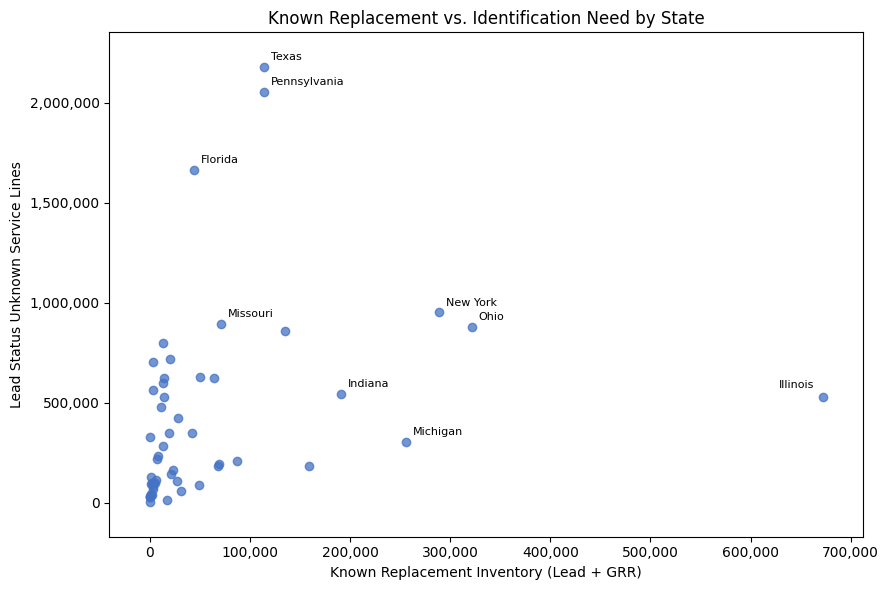

In [25]:
highlight_states = set(
    state_summary.nlargest(5, "Known_Replacement")["State"]
) | set(
    state_summary.nlargest(5, "Unknown")["State"]
)

label_offsets = {
    "Illinois": (-6, 6)
}

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    state_summary["Known_Replacement"],
    state_summary["Unknown"],
    color="#4472C4",
    alpha=0.75
)

for _, row in state_summary[state_summary["State"].isin(highlight_states)].iterrows():
    offset = label_offsets.get(row["State"], (5, 5))
    ax.annotate(
        row["State"],
        (row["Known_Replacement"], row["Unknown"]),
        xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left",
        fontsize=8
    )

ax.set_xlabel("Known Replacement Inventory (Lead + GRR)")
ax.set_ylabel("Lead Status Unknown Service Lines")
ax.set_title("Known Replacement vs. Identification Need by State")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.margins(x=0.06, y=0.08)

fig.tight_layout()
fig.savefig("outputs/chart_4_replacement_vs_identification.png", dpi=300, bbox_inches="tight")
plt.show()

### Relationship Between the Two Needs

The scatterplot shows that high replacement and identification needs do not always occur together. Illinois has the largest known replacement inventory, while Texas and Pennsylvania have much larger unresolved inventories. States such as Ohio and New York stand out on both dimensions, suggesting that different states may be at different stages of the service-line identification and replacement process.

In 49 of the 51 jurisdictions (50 states and DC), Lead Status Unknown inventory exceeds Known Replacement Inventory, showing that identification is the larger reported need across most states.

## 12. Population Context

Raw state totals are influenced by state size, so the analysis also compares service-line inventories relative to population.

The EPA file includes `Population Served Count` at the water-system level, but summing those values across a state may not represent a unique state population. To create a more consistent denominator, this analysis uses **2025 U.S. Census resident population estimates**.

Supplemental population source: U.S. Census Bureau, July 1, 2025 resident population estimates.

**Official source:** [U.S. Census Bureau 2025 resident population estimates](https://www.census.gov/data/datasets/time-series/demo/popest/2020s-national-detail.html)

Because the Census data is only used as a recent size-adjustment benchmark, the one-year timing difference from the 2026 Q2 EPA inventory is considered acceptable.

Normalized measures are reported per **10,000 state residents** and should be interpreted as context for state size, not as direct estimates of affected customers.
    

In [26]:
census_raw = pd.read_csv(
    "SCPRC-EST2025-18+POP.csv",
    header=None
)

census = census_raw.iloc[:, [0, 1]].copy()
census.columns = ["State", "Population_2025"]

census = census[
    census["State"].astype(str).str.startswith(".")
].copy()

census["State"] = census["State"].str.lstrip(".")

census["Population_2025"] = pd.to_numeric(
    census["Population_2025"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

census.head()

,State,Population_2025
9,Alabama,5193088
10,Alaska,737270
11,Arizona,7623818
12,Arkansas,3114791
13,California,39355309


In [27]:
print(f"Rows in Census state table: {len(census)}")
print(f"Missing population values: {census['Population_2025'].isna().sum()}")

Rows in Census state table: 51
Missing population values: 0


In [28]:
state_summary = state_summary.merge(
    census,
    on="State",
    how="left"
)

print(f"Rows after merge: {len(state_summary)}")
print(f"Missing Census populations: {state_summary['Population_2025'].isna().sum()}")

Rows after merge: 51
Missing Census populations: 0


In [29]:
state_summary["Known_Replacement_per_10k"] = (
    state_summary["Known_Replacement"]
    / state_summary["Population_2025"]
    * 10000
)

state_summary["Unknown_per_10k"] = (
    state_summary["Unknown"]
    / state_summary["Population_2025"]
    * 10000
)

In [30]:
state_summary.sort_values(
    "Known_Replacement_per_10k",
    ascending=False
)[
    ["State", "Known_Replacement_per_10k", "Known_Replacement"]
].head(10)

,State,Known_Replacement_per_10k,Known_Replacement
13,Illinois,528.502672,672210
39,Rhode Island,282.533932,31489
14,Indiana,273.824583,190947
35,Ohio,270.15817,321502
49,Wisconsin,265.897645,158815
22,Michigan,252.297518,255524
8,District of Columbia,247.316711,17155
27,Nebraska,241.386795,48712
15,Iowa,209.826682,67950
23,Minnesota,149.531636,87183


In [31]:
state_summary.sort_values(
    "Unknown_per_10k",
    ascending=False
)[
    ["State", "Unknown_per_10k", "Unknown"]
].head(10)


,State,Unknown_per_10k,Unknown
38,Pennsylvania,1573.967382,2055512
18,Louisiana,1557.106043,719101
31,New Mexico,1539.921468,327310
3,Arkansas,1534.375822,477926
36,Oklahoma,1511.728019,623329
25,Missouri,1427.329795,895013
50,Wyoming,1373.615081,80872
48,West Virginia,1313.741155,232026
34,North Dakota,1225.35835,97950
7,Delaware,1069.482392,113360


In [32]:
raw_known_top10 = set(
    state_summary.nlargest(10, "Known_Replacement")["State"]
)

normalized_known_top10 = set(
    state_summary.nlargest(10, "Known_Replacement_per_10k")["State"]
)

raw_unknown_top10 = set(
    state_summary.nlargest(10, "Unknown")["State"]
)

normalized_unknown_top10 = set(
    state_summary.nlargest(10, "Unknown_per_10k")["State"]
)

print(
    "Known Replacement top-10 overlap:",
    len(raw_known_top10 & normalized_known_top10),
    "of 10"
)

print(
    "Unknown top-10 overlap:",
    len(raw_unknown_top10 & normalized_unknown_top10),
    "of 10"
)


Known Replacement top-10 overlap: 6 of 10
Unknown top-10 overlap: 3 of 10


In [33]:
print("Entered normalized Known Replacement top 10:")
print(sorted(normalized_known_top10 - raw_known_top10))

print("\nDropped from raw Known Replacement top 10:")
print(sorted(raw_known_top10 - normalized_known_top10))

print("\nEntered normalized Unknown top 10:")
print(sorted(normalized_unknown_top10 - raw_unknown_top10))

print("\nDropped from raw Unknown top 10:")
print(sorted(raw_unknown_top10 - normalized_unknown_top10))

Entered normalized Known Replacement top 10:
['District of Columbia', 'Iowa', 'Nebraska', 'Rhode Island']

Dropped from raw Known Replacement top 10:
['New Jersey', 'New York', 'Pennsylvania', 'Texas']

Entered normalized Unknown top 10:
['Arkansas', 'Delaware', 'New Mexico', 'North Dakota', 'Oklahoma', 'West Virginia', 'Wyoming']

Dropped from raw Unknown top 10:
['Arizona', 'Florida', 'New Jersey', 'New York', 'North Carolina', 'Ohio', 'Texas']


### Population-Adjusted Pattern

Accounting for population changes the state-level picture substantially. Several smaller states rise into the top normalized rankings even though they do not have the largest raw inventories.

This suggests that absolute counts and population-adjusted measures answer different questions: raw totals show where the largest overall workloads are concentrated, while per-capita measures show where those inventories are large relative to state population.

## 13. Final Visualizations

The strongest charts are refined for the final data story using the validated state-level results.

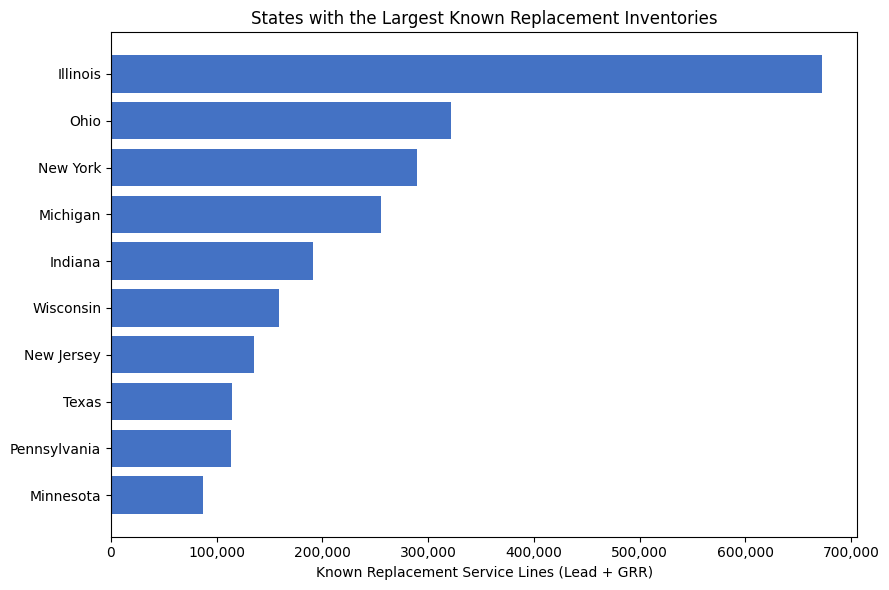

In [34]:
top_known_chart = (
    state_summary.nlargest(10, "Known_Replacement")
    .sort_values("Known_Replacement")
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_known_chart["State"],
    top_known_chart["Known_Replacement"],
    color="#4472C4"
)

ax.set_title("States with the Largest Known Replacement Inventories")
ax.set_xlabel("Known Replacement Service Lines (Lead + GRR)")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

fig.tight_layout()
fig.savefig("outputs/chart_2_known_replacement.png", dpi=300, bbox_inches="tight")
plt.show()

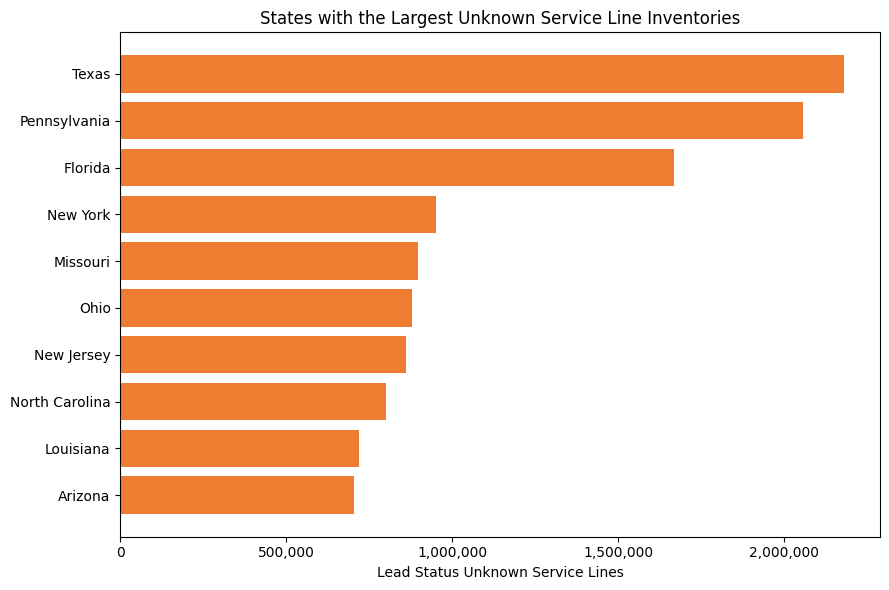

In [35]:
top_unknown_chart = (
    state_summary.nlargest(10, "Unknown")
    .sort_values("Unknown")
)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_unknown_chart["State"],
    top_unknown_chart["Unknown"],
    color="#ED7D31"
)

ax.set_title("States with the Largest Unknown Service Line Inventories")
ax.set_xlabel("Lead Status Unknown Service Lines")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")

fig.tight_layout()
fig.savefig("outputs/chart_3_unknown_lines.png", dpi=300, bbox_inches="tight")
plt.show()

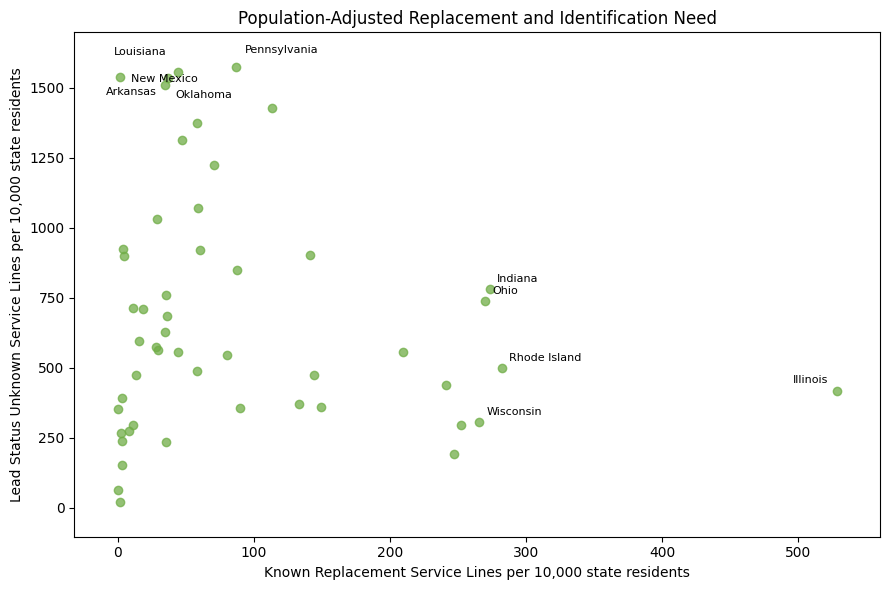

In [36]:
normalized_highlights = set(
    state_summary.nlargest(5, "Known_Replacement_per_10k")["State"]
) | set(
    state_summary.nlargest(5, "Unknown_per_10k")["State"]
)

normalized_label_offsets = {
    "Pennsylvania": (6, 10),
    "Louisiana": (-8, 12),
    "New Mexico": (8, -4),
    "Arkansas": (-8, -12),
    "Oklahoma": (8, -10),
    "Illinois": (-6, 6)
}

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    state_summary["Known_Replacement_per_10k"],
    state_summary["Unknown_per_10k"],
    color="#70AD47",
    alpha=0.75
)

for _, row in state_summary[state_summary["State"].isin(normalized_highlights)].iterrows():
    offset = normalized_label_offsets.get(row["State"], (5, 5))
    ax.annotate(
        row["State"],
        (row["Known_Replacement_per_10k"], row["Unknown_per_10k"]),
        xytext=offset,
        textcoords="offset points",
        ha="right" if offset[0] < 0 else "left",
        fontsize=8
    )

ax.set_title("Population-Adjusted Replacement and Identification Need")
ax.set_xlabel("Known Replacement Service Lines per 10,000 state residents")
ax.set_ylabel("Lead Status Unknown Service Lines per 10,000 state residents")
ax.margins(x=0.06, y=0.08)

fig.tight_layout()
fig.savefig("outputs/chart_5_normalized.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
state_summary[
    [
        "State",
        "Systems",
        "Lead",
        "GRR",
        "Known_Replacement",
        "Unknown",
        "Population_2025",
        "Known_Replacement_per_10k",
        "Unknown_per_10k"
    ]
].to_csv("outputs/state_service_line_summary.csv", index=False)

expected_outputs = [
    Path("outputs/chart_1_inventory.png"),
    Path("outputs/chart_2_known_replacement.png"),
    Path("outputs/chart_3_unknown_lines.png"),
    Path("outputs/chart_4_replacement_vs_identification.png"),
    Path("outputs/chart_5_normalized.png"),
    Path("outputs/state_service_line_summary.csv")
]

missing_outputs = [path for path in expected_outputs if not path.exists()]

assert not missing_outputs, f"Missing outputs: {missing_outputs}"

print("All six required output files were created.")

All six required output files were created.


## 14. Key Findings

- The analytical sample contains **3,115,308 known replacement service lines** (Lead + GRR) and **21,589,524 Lead Status Unknown service lines**, showing that unresolved identification is substantially larger than the already-classified replacement inventory.
- Known replacement inventory is most concentrated in **Illinois (672,210)**, followed by **Ohio (321,502)** and **New York (289,055)**.
- Identification need is largest in **Texas (2,178,881 Unknown service lines)**, **Pennsylvania (2,055,512)**, and **Florida (1,665,928)**. Only five states appear in both raw top-10 lists, so replacement and identification workloads are not concentrated in exactly the same places.
- Population adjustment changes the interpretation: Illinois remains highest for known replacement inventory at **528.5 per 10,000 residents**, while Pennsylvania leads Unknown inventory at **1,574.0 per 10,000 residents**. The raw and normalized top-10 lists overlap for only **6 of 10** known replacement states and **3 of 10** Unknown states.

## 15. Limitations

- Lead Status Unknown does not mean lead.
- These data describe infrastructure inventories, not household exposure or water quality.
- State aggregation hides utility-level and local variation.
- The analysis includes only Community Water Systems that reported all required service-line types; incomplete reports are omitted and state inventories may therefore be understated where reporting gaps are greater.
- Territories, Navajo Nation, and directly administered EPA regional records are excluded from the state comparison.
- Normalization uses 2025 Census resident population as a size benchmark for 2026 Q2 EPA inventory data.
- Per-capita values are contextual rates, not estimates of affected customers.

## 16. Practical Implications

States with large known replacement inventories face substantial already-identified replacement workloads, while states with large Unknown inventories face substantial identification and inventory-completion workloads. High levels of both indicate that work remains at multiple stages.

This is a high-level needs assessment that can indicate where deeper investigation may be valuable. Utility-level records, GIS information, inspections, funding, project plans, and other local information would be required to determine actual interventions.

## 17. Recommended Next Question

**How do state and utility identification and replacement needs align with available funding and local capacity to complete service-line replacement?**